\
# 07. 非ユークリッド多様体レイアウト（双曲ポアンカレ／ローレンツ・球面・トーラス）

このノートブックでは、`egraph` v6 が提供する 4 種の非ユークリッド多様体（**双曲ポアンカレ円板・双曲ローレンツ双曲面・単位 2 次元球面 $S^2$・平坦 2 次元トーラス $T^2$**）上のグラフレイアウト計算 API を学びます。

### このノートブックで扱う主な機能
- `ManifoldLayout2d`: 4 種の多様体表現（`"hyperbolic"`, `"hyperbolic_lorentz"`, `"spherical"`, `"torus"`）と `ManifoldMetric`（`scale`・`aspect`・`set_torus_extents`・`rescale_geodesic`）・`to_poincare_layout()`
- 双曲測地線・メビウス変換・ローレンツモデル接空間演算（`poincare_*`, `lorentz_*`）
- 全 17 種 `SgdSolver`（`reset_schedule` / `run_schedule_window` 含む）および 6 種多様体対応ソルバ（`SgdSolver`, `StressMajorizationSolver`, `KamadaKawaiSolver`, `FruchtermanReingoldSolver`, `TsNetSolver`, `GuMapSolver`）の統一 `.step(m)` / `.run(m)`
- トーラス位相初期化（`torus_spectral_phase_init`）・自動センタリング（`torus_auto_pan`）・`torus_layout_edge_segments`・球面/双曲/トーラス交差数 & `geodesic_distortion`
- `resistance_curvature_flow`（既定 `exact_max_nodes=256`）による最適多様体の自動推薦
- `matplotlib` による双曲測地線アーク・3D 球面大円アーク・トーラス周期境界の可視化

In [ ]:
!pip install -q --pre "egraph==6.0.0a8" matplotlib-fontja

## 1. インポートと多様体可視化ヘルパー関数の定義

`egraph` は多様体上の座標計算と測地線・接空間演算のみを担当し、描画はすべて `matplotlib`（2D `LineCollection` / 3D `Line3DCollection`）で実装します。
各多様体の幾何学的特徴を正確に描画するため、以下の 3 つの可視化ヘルパーを定義します。

1. **ポアンカレ円板 (`plot_poincare_disk`)**: 単位円に直交する円弧（双曲測地線）を厳密計算して描画
2. **単位球面 $S^2$ (`plot_spherical_3d`)**: `(lon, colat)` を `Z`-up 3 次元座標へ変換し、球面線形補間（SLERP）で大円アークを描画
3. **単位トーラス $T^2$ (`plot_torus_2d`)**: $[0, 1)^2$ 上の最短周期イメージを計算し、Liang-Barsky クリッピングで境界を跨ぐ辺を分割描画（交差辺ハイライト対応）

In [ ]:
import math
import time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection

# Apply Japanese font on Colab when matplotlib-fontja is installed
try:
    import matplotlib_fontja  # noqa: F401
except ImportError:
    pass

import egraph as eg
from egraph.interop import from_networkx

plt.rcParams["figure.dpi"] = 120
print(f"egraph version: {eg.__version__}")


def _unique_undirected_edges(graph: eg.CsrGraph) -> list[tuple[int, int]]:
    '''Extract unique undirected edges (u < v) from a CsrGraph.'''
    indptr = graph.indptr()
    indices = graph.indices()
    edges = []
    for u in range(graph.num_nodes):
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]:
            v_int = int(v)
            if u < v_int:
                edges.append((u, v_int))
    return edges


def _poincare_geodesic_arc(p1: np.ndarray, p2: np.ndarray, n_pts: int = 24) -> np.ndarray:
    '''Compute exact orthogonal circle geodesic arc between two points in the Poincare disk.'''
    x1, y1 = float(p1[0]), float(p1[1])
    x2, y2 = float(p2[0]), float(p2[1])
    det = x1 * y2 - y1 * x2
    norm1 = math.hypot(x1, y1)
    norm2 = math.hypot(x2, y2)
    dist = math.hypot(x2 - x1, y2 - y1)

    if dist < 1e-8 or abs(det) < 1e-8 * (norm1 * norm2 + 1e-12):
        return np.vstack([p1, p2])

    b1 = 0.5 * (1.0 + x1 * x1 + y1 * y1)
    b2 = 0.5 * (1.0 + x2 * x2 + y2 * y2)
    cx = (b1 * y2 - b2 * y1) / det
    cy = (x1 * b2 - x2 * b1) / det
    radius = math.hypot(x1 - cx, y1 - cy)
    if radius > 1e4 or not math.isfinite(radius):
        return np.vstack([p1, p2])

    a1 = math.atan2(y1 - cy, x1 - cx)
    a2 = math.atan2(y2 - cy, x2 - cx)
    da = (a2 - a1 + math.pi) % (2.0 * math.pi) - math.pi
    angles = np.linspace(a1, a1 + da, n_pts)
    return np.column_stack([cx + radius * np.cos(angles), cy + radius * np.sin(angles)])


def plot_poincare_disk(
    graph: eg.CsrGraph,
    m_layout: eg.ManifoldLayout2d,
    ax=None,
    *,
    title: str = "",
    node_color="#1f77b4",
    node_size: float = 28.0,
    edge_alpha: float = 0.45,
    highlight_idx: int | None = None,
):
    '''Plot a hyperbolic ManifoldLayout2d on the Poincare unit disk with geodesic arcs.'''
    if ax is None:
        _, ax = plt.subplots(figsize=(5.0, 5.0))

    coords = m_layout.coords()
    edges = _unique_undirected_edges(graph)
    arcs = [_poincare_geodesic_arc(coords[u], coords[v]) for u, v in edges]

    boundary = plt.Circle((0.0, 0.0), 1.0, fill=False, color="#333333", linewidth=1.3, zorder=1)
    ax.add_patch(boundary)
    if arcs:
        lc = LineCollection(arcs, colors="#5c6bc0", linewidths=0.85, alpha=edge_alpha, zorder=2)
        ax.add_collection(lc)

    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        s=node_size,
        c=node_color,
        edgecolors="white",
        linewidths=0.4,
        zorder=3,
    )
    if highlight_idx is not None:
        ax.scatter(
            [coords[highlight_idx, 0]],
            [coords[highlight_idx, 1]],
            s=node_size * 3.0,
            c="#d62728",
            marker="*",
            edgecolors="black",
            linewidths=0.6,
            zorder=4,
            label=f"注目頂点 {highlight_idx}",
        )
        ax.legend(loc="upper right", fontsize=8, framealpha=0.9)

    ax.set_xlim(-1.08, 1.08)
    ax.set_ylim(-1.08, 1.08)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)
    return ax


def _slerp_arc(p1: np.ndarray, p2: np.ndarray, n_pts: int = 16) -> np.ndarray:
    '''Compute great-circle SLERP arc between two 3D unit vectors.'''
    dot = float(np.clip(np.dot(p1, p2), -1.0, 1.0))
    omega = math.acos(dot)
    ts = np.linspace(0.0, 1.0, n_pts)[:, None]
    if omega < 1e-7:
        pts = (1.0 - ts) * p1 + ts * p2
    elif math.pi - omega < 1e-5:
        # Pick an orthogonal axis for nearly antipodal points
        ref = np.array([1.0, 0.0, 0.0]) if abs(p1[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
        ortho = np.cross(p1, ref)
        ortho /= np.linalg.norm(ortho)
        pts = np.cos(ts * math.pi) * p1 + np.sin(ts * math.pi) * ortho
    else:
        sin_o = math.sin(omega)
        pts = (np.sin((1.0 - ts) * omega) * p1 + np.sin(ts * omega) * p2) / sin_o
    norms = np.linalg.norm(pts, axis=1, keepdims=True)
    return pts / np.maximum(norms, 1e-12)


def plot_spherical_3d(
    graph: eg.CsrGraph,
    m_layout: eg.ManifoldLayout2d,
    ax=None,
    *,
    title: str = "",
    node_color: str = "#1f77b4",
    node_size: float = 36.0,
    elev: float = 20.0,
    azim: float = 35.0,
):
    '''Plot a spherical ManifoldLayout2d (lon, colat) on a 3D unit sphere using Z-up mapping.'''
    if ax is None:
        fig = plt.figure(figsize=(5.2, 4.8))
        ax = fig.add_subplot(111, projection="3d")

    coords = m_layout.coords()
    lon = coords[:, 0]
    colat = coords[:, 1]
    xyz = np.column_stack([
        np.sin(colat) * np.cos(lon),
        np.sin(colat) * np.sin(lon),
        np.cos(colat),
    ])

    # Translucent unit sphere wireframe
    u = np.linspace(0.0, 2.0 * np.pi, 32)
    v = np.linspace(0.0, np.pi, 18)
    sx = np.outer(np.cos(u), np.sin(v))
    sy = np.outer(np.sin(u), np.sin(v))
    sz = np.outer(np.ones_like(u), np.cos(v))
    ax.plot_wireframe(sx, sy, sz, rstride=2, cstride=2, color="#bbbbbb", alpha=0.22, linewidth=0.5)

    edges = _unique_undirected_edges(graph)
    arcs = [_slerp_arc(xyz[u_i], xyz[v_i]) for u_i, v_i in edges]
    if arcs:
        lc = Line3DCollection(arcs, colors="#2e7d32", linewidths=1.05, alpha=0.75)
        ax.add_collection3d(lc)

    ax.scatter(xyz[:, 0], xyz[:, 1], xyz[:, 2], s=node_size, c=node_color, edgecolors="white", linewidths=0.4, depthshade=True)
    ax.set_xlim(-1.05, 1.05)
    ax.set_ylim(-1.05, 1.05)
    ax.set_zlim(-1.05, 1.05)
    ax.set_box_aspect([1.0, 1.0, 1.0])
    ax.view_init(elev=elev, azim=azim)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])
    if title:
        ax.set_title(title, fontsize=10)
    return ax


def _clip_segment_unit_square(x0: float, y0: float, x1: float, y1: float):
    '''Clip a 2D line segment against [0, 1]^2 using Liang-Barsky.'''
    dx = x1 - x0
    dy = y1 - y0
    t0, t1 = 0.0, 1.0
    for p, q in [(-dx, x0), (dx, 1.0 - x0), (-dy, y0), (dy, 1.0 - y0)]:
        if abs(p) < 1e-12:
            if q < 0.0:
                return None
        else:
            r = q / p
            if p < 0.0:
                if r > t1:
                    return None
                if r > t0:
                    t0 = r
            else:
                if r < t0:
                    return None
                if r < t1:
                    t1 = r
    return [(x0 + t0 * dx, y0 + t0 * dy), (x0 + t1 * dx, y0 + t1 * dy)]


def plot_torus_2d(
    graph: eg.CsrGraph,
    m_layout: eg.ManifoldLayout2d,
    ax=None,
    *,
    title: str = "",
    crossings: list[dict] | None = None,
    node_color: str = "#1f77b4",
    node_size: float = 26.0,
):
    '''Plot a torus ManifoldLayout2d on [0, 1)^2 with periodic wrap-around clipping.'''
    if ax is None:
        _, ax = plt.subplots(figsize=(5.0, 5.0))

    coords = np.mod(m_layout.coords(), 1.0)
    edges = _unique_undirected_edges(graph)
    segments = []
    for u, v in edges:
        px, py = float(coords[u, 0]), float(coords[u, 1])
        qx, qy = float(coords[v, 0]), float(coords[v, 1])
        best_dx, best_dy, best_d = 0, 0, float("inf")
        for dx in (-1, 0, 1):
            for dy in (-1, 0, 1):
                d = math.hypot(px + dx - qx, py + dy - qy)
                if d < best_d:
                    best_dx, best_dy, best_d = dx, dy, d
        sx_list = [0] if best_dx == 0 else [0, -best_dx]
        sy_list = [0] if best_dy == 0 else [0, -best_dy]
        for sx in sx_list:
            for sy in sy_list:
                clipped = _clip_segment_unit_square(px + best_dx + sx, py + best_dy + sy, qx + sx, qy + sy)
                if clipped is not None:
                    segments.append(clipped)

    ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], color="#333333", linestyle="--", linewidth=1.1, zorder=1)
    if segments:
        lc = LineCollection(segments, colors="#78909c", linewidths=0.85, alpha=0.65, zorder=2)
        ax.add_collection(lc)

    if crossings:
        cross_segs = []
        for c in crossings:
            sa = c["seg_a"]
            sb = c["seg_b"]
            cross_segs.append([(sa[0], sa[1]), (sa[2], sa[3])])
            cross_segs.append([(sb[0], sb[1]), (sb[2], sb[3])])
        lc_cross = LineCollection(cross_segs, colors="#d62728", linewidths=1.35, alpha=0.85, zorder=3)
        ax.add_collection(lc_cross)

    ax.scatter(coords[:, 0], coords[:, 1], s=node_size, c=node_color, edgecolors="white", linewidths=0.35, zorder=4)
    ax.set_xlim(-0.04, 1.04)
    ax.set_ylim(-0.04, 1.04)
    ax.set_aspect("equal")
    ax.set_xlabel("x (周期境界 [0, 1))")
    ax.set_ylabel("y (周期境界 [0, 1))")
    if title:
        ax.set_title(title, fontsize=10)
    return ax

egraph version: 6.0.0a8


\
## 2. `ManifoldLayout2d` のコンストラクタ・座標規約・`ManifoldMetric`

`ManifoldLayout2d` は 4 種類の多様体をサポートします。エイリアス文字列は内部で正規化されます（大文字・小文字や `_` / `-` / 空白を無視）。

| 正規化名 (`.kind`) | 指定可能な文字列 | 座標の意味・領域 |
|---|---|---|
| `"hyperbolic"` | `"hyperbolic"`, `"poincare"`, `"hyperbolic_poincare"` | ポアンカレ開単位円板 $\\|p\\|_2 < 1$（$1 - \\varepsilon$ に射影） |
| `"hyperbolic_lorentz"` | `"hyperbolic_lorentz"`, `"lorentz"`, `"hyperboloid"` | ローレンツ双曲面上の極投影座標（`to_poincare_layout()` でポアンカレ円板へ変換可） |
| `"spherical"` | `"spherical"`, `"sphere"` | 経度・余緯度 $(\\lambda, \\phi) \\in [0, 2\\pi) \\times [0, \\pi]$（ラジアン） |
| `"torus"` | `"torus"`, `"torus_2d"` | 平坦トーラス $[0, L_x) \\times [0, L_y)$（既定 $L_x = L_y = 1.0$、`set_torus_extents` でアスペクト変更可） |

`ManifoldLayout2d` は `.kind` と `len(m)` を公開し、`coords(copy=False)` によるゼロコピー取得や `ManifoldMetric`（`.scale`, `.aspect`, `.metric()`, `.set_scale()`, `.set_aspect()`, `.rescale_geodesic()`）を備えています。

In [ ]:
\
# 1) All constructors and canonical kind aliases (including hyperbolic_lorentz)
m_zeros = eg.ManifoldLayout2d.zeros("poincare", 6, dtype="float64")
m_hyp_zero = eg.ManifoldLayout2d.hyperbolic_poincare(6, dtype="float32")
m_lor_zero = eg.ManifoldLayout2d.hyperbolic_lorentz(6)
m_lor_init = eg.ManifoldLayout2d.init("lorentz", 6, scale=0.3, seed=42)
m_lor_poinc = m_lor_init.to_poincare_layout()
m_sph_zero = eg.ManifoldLayout2d.spherical(6)
m_tor_zero = eg.ManifoldLayout2d.torus_2d(6)
m_sph_alias = eg.ManifoldLayout2d.random_init("sphere", 6, seed=42)
m_tor_alias = eg.ManifoldLayout2d.random_init("torus2d", 6, seed=42)

print(
    f"zeros('poincare'): kind={m_zeros.kind!r}, dtype={m_zeros.dtype!r}, "
    f"num_nodes={m_zeros.num_nodes}, len={len(m_zeros)}, "
    f"is_empty={m_zeros.is_empty()}, finite={m_zeros.is_all_finite()}"
)
print(
    f"Aliases -> lorentz={m_lor_zero.kind!r} -> to_poincare={m_lor_poinc.kind!r}, "
    f"spherical={m_sph_alias.kind!r}, torus2d={m_tor_alias.kind!r}, f32={m_hyp_zero.dtype!r}"
)

# ManifoldMetric & coords(copy=False)
print(f"Initial metric: scale={m_zeros.scale}, aspect={m_zeros.aspect}, tuple={m_zeros.metric()}")
m_tor_zero.set_torus_extents(1.6, 1.0)
print(f"After set_torus_extents(1.6, 1.0): metric={m_tor_zero.metric()}")
m_lor_init.rescale_geodesic(0.8)
print(f"After rescale_geodesic(0.8) on lorentz: scale={m_lor_init.scale}")

# 2) from_coords, from_layout, from_layout_scaled, to_layout
raw_coords = np.array([[2.0, 0.0], [0.0, 0.5], [-0.3, 0.4], [0.1, -0.2]])
m_from_c = eg.ManifoldLayout2d.from_coords("hyperbolic", raw_coords)
euc_layout = eg.Layout2d.from_coords(raw_coords)
m_from_l = eg.ManifoldLayout2d.from_layout("torus", euc_layout)
m_scaled = eg.ManifoldLayout2d.from_layout_scaled("hyperbolic", euc_layout, max_radius=0.7)

print(f"from_coords projection of [2.0, 0.0] -> ({m_from_c.x(0):.6f}, {m_from_c.y(0):.6f})")
print(f"from_layout('torus') [2.0, 0.0] -> ({m_from_l.x(0):.4f}, {m_from_l.y(0):.4f})")
r_scaled = np.linalg.norm(m_scaled.coords(copy=False), axis=1).max()
print(f"from_layout_scaled(max_radius=0.7) max radius: {r_scaled:.6f}")

# Convert back to Euclidean Layout2d
back_layout = m_scaled.to_layout()
print("to_layout() type:", type(back_layout).__name__, "shape:", back_layout.coords(copy=False).shape)

# 3) Point setter, geodesic_distance, tangent_delta, apply_tangent_step, project_all
m_edit = eg.ManifoldLayout2d.init("hyperbolic", 4, scale=0.3, seed=7)
m_edit.set_point(0, 1.5, 0.0)  # Projected inside open unit disk
m_edit.set_point(1, 0.0, 0.4)
d01 = m_edit.geodesic_distance(0, 1)
vx, vy = m_edit.tangent_delta(0, 1)
print(f"Before tangent step: d(0,1)={d01:.4f}, log_0(1)=({vx:.4f}, {vy:.4f})")
m_edit.apply_tangent_step(0, 0.3 * vx, 0.3 * vy)
m_edit.project_all()
print(f"After 0.3x tangent step toward 1: d(0,1)={m_edit.geodesic_distance(0, 1):.4f}")

# 4) Verify Poincare-only operations reject non-poincare manifolds
for bad_m in (m_sph_alias, m_tor_alias):
    try:
        bad_m.poincare_centroid()
    except ValueError as err:
        print(f"Expected ValueError on {bad_m.kind}: {err}")

zeros('poincare'): kind='hyperbolic', dtype='float64', num_nodes=6, len=6, is_empty=False, finite=True
Aliases -> lorentz='hyperbolic_lorentz' -> to_poincare='hyperbolic', spherical='spherical', torus2d='torus', f32='float32'
Initial metric: scale=1.0, aspect=1.0, tuple=(1.0, 1.0)
After set_torus_extents(1.6, 1.0): metric=(1.0, 1.6)
After rescale_geodesic(0.8) on lorentz: scale=0.8
from_coords projection of [2.0, 0.0] -> (0.999990, 0.000000)
from_layout('torus') [2.0, 0.0] -> (0.0000, 0.0000)
from_layout_scaled(max_radius=0.7) max radius: 0.700000
to_layout() type: Layout2d shape: (4, 2)
Before tangent step: d(0,1)=12.5288, log_0(1)=(-12.5288, 0.0001)
After 0.3x tangent step toward 1: d(0,1)=8.7702
Expected ValueError on spherical: unsupported operation: poincare_centroid is only supported on HyperbolicPoincare manifolds
Expected ValueError on torus: unsupported operation: poincare_centroid is only supported on HyperbolicPoincare manifolds


\
## 3. 単体測地線ヘルパー（ポアンカレ・ローレンツ・球面・トーラス）とメビウス変換

`egraph` には `ManifoldLayout2d` インスタンスを作らずに直接座標ペアで計算できる測地線ヘルパーが用意されています。
- `poincare_distance(x1, y1, x2, y2)` / `poincare_mobius_add(x1, y1, x2, y2)` / `poincare_einstein_midpoint(xs, ys)`
- `lorentz_distance(x1, y1, x2, y2)` / `lorentz_to_poincare_point(x, y)` / `lorentz_exp_map` / `lorentz_log_map` / `lorentz_einstein_midpoint`
- `spherical_distance(lon1, colat1, lon2, colat2)`
- `torus_distance(x1, y1, x2, y2)` / `wrap_torus_point(x, y)`

ポアンカレ円板では **メビウス変換（Möbius automorphism）** が双曲距離を完全に保つ等長変換（isometry）になります。
そのため `recenter_poincare(cx, cy)`・`recenter_poincare_at(index)`・`center_poincare_centroid()` を使って注目頂点やアインシュタイン重心 (`poincare_centroid()`) を円板中心 `(0, 0)` に移動すると、元のレイアウトの双曲距離を一切変えずに中心付近を拡大して観察（**Focus+Context**）できます。

poincare_distance((0,0), (0.5,0)) = 1.098612 (exact atanh(0.5)*2 = 1.098612)
lorentz_distance((0,0), (0.8,0))  = 0.732668 | to_poincare=(0.3508, 0.0000)
poincare_mobius_add((0.3,0.2), (-0.3,-0.2)) = (0.00e+00, 0.00e+00)
spherical_distance(north pole, equator) = 1.570796 (pi/2 = 1.570796)
torus_distance((0.05,0.05), (0.95,0.95)) = 0.141421 (0.1*sqrt(2) = 0.141421)
wrap_torus_point(1.25, -0.2) = (0.2500, 0.8000)


lesmis Einstein centroid before centering: (0.2211, -0.0946), centroid after center_poincare_centroid(): (0.0, 0.0)
Isometry check d(11, 1): before=2.43431132, after=2.43431132, diff=8.88e-16


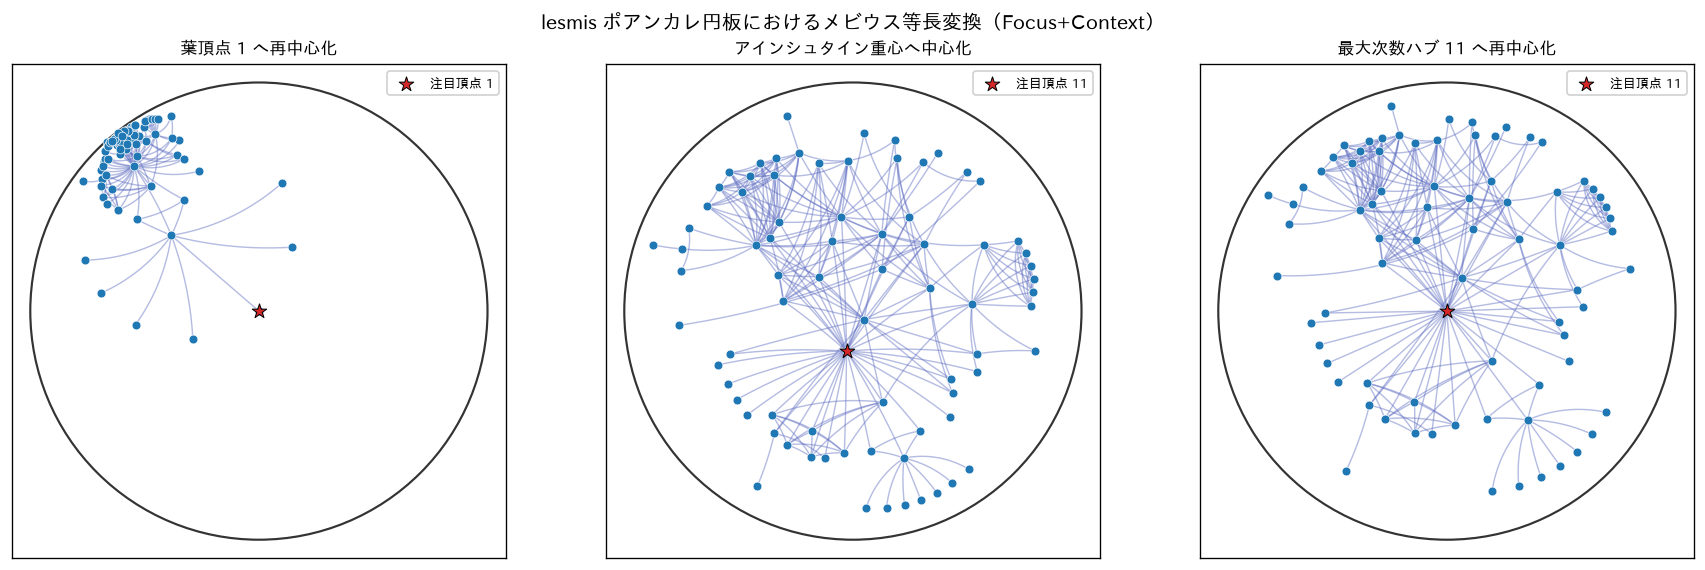

In [ ]:
\
# 1) Standalone geodesic helpers & Lorentz <-> Poincare consistency check
d_poinc = eg.poincare_distance(0.0, 0.0, 0.5, 0.0)
mx, my = eg.poincare_mobius_add(0.3, 0.2, -0.3, -0.2)
px_l, py_l = eg.lorentz_to_poincare_point(0.8, 0.0)
d_lor = eg.lorentz_distance(0.0, 0.0, 0.8, 0.0)
d_sph = eg.spherical_distance(0.0, 0.0, 0.0, math.pi / 2.0)  # North pole to equator = pi/2
d_tor = eg.torus_distance(0.05, 0.05, 0.95, 0.95)          # Periodic wrap: sqrt(0.1^2 + 0.1^2)
wx, wy = eg.wrap_torus_point(1.25, -0.2)

print(f"poincare_distance((0,0), (0.5,0)) = {d_poinc:.6f} (exact atanh(0.5)*2 = {2*math.atanh(0.5):.6f})")
print(f"lorentz_distance((0,0), (0.8,0))  = {d_lor:.6f} | to_poincare=({px_l:.4f}, {py_l:.4f})")
print(f"poincare_mobius_add((0.3,0.2), (-0.3,-0.2)) = ({mx:.2e}, {my:.2e})")
print(f"spherical_distance(north pole, equator) = {d_sph:.6f} (pi/2 = {math.pi/2:.6f})")
print(f"torus_distance((0.05,0.05), (0.95,0.95)) = {d_tor:.6f} (0.1*sqrt(2) = {0.1*math.sqrt(2):.6f})")
print(f"wrap_torus_point(1.25, -0.2) = ({wx:.4f}, {wy:.4f})")

# 2) Hyperbolic layout on 'lesmis' + Mobius recentering isometry check
g_les = eg.load_dataset("lesmis")
m_les = eg.ManifoldLayout2d.init("hyperbolic", g_les.num_nodes, scale=0.35, seed=42)
eg.SgdSolver.full(g_les, iterations=80, seed=42).run(m_les)

degs = [g_les.degree(i) for i in range(g_les.num_nodes)]
hub_idx = int(np.argmax(degs))
leaf_idx = int(np.argmin(degs))
dist_before = m_les.geodesic_distance(hub_idx, leaf_idx)

# Copy via coords to compare three isometric views of the same hyperbolic layout
m_leaf_centered = eg.ManifoldLayout2d.from_coords("hyperbolic", m_les.coords())
m_leaf_centered.recenter_poincare_at(leaf_idx)

m_centroid_centered = eg.ManifoldLayout2d.from_coords("hyperbolic", m_les.coords())
cx_e, cy_e = m_centroid_centered.poincare_centroid()
m_centroid_centered.center_poincare_centroid()

m_hub_centered = eg.ManifoldLayout2d.from_coords("hyperbolic", m_les.coords())
m_hub_centered.recenter_poincare(m_hub_centered.x(hub_idx), m_hub_centered.y(hub_idx))

dist_after = m_hub_centered.geodesic_distance(hub_idx, leaf_idx)
print(
    f"lesmis Einstein centroid before centering: ({cx_e:.4f}, {cy_e:.4f}), "
    f"centroid after center_poincare_centroid(): {tuple(round(v, 6) for v in m_centroid_centered.poincare_centroid())}"
)
print(f"Isometry check d({hub_idx}, {leaf_idx}): before={dist_before:.8f}, after={dist_after:.8f}, diff={abs(dist_before - dist_after):.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.8))
plot_poincare_disk(g_les, m_leaf_centered, ax=axes[0], title=f"葉頂点 {leaf_idx} へ再中心化", highlight_idx=leaf_idx)
plot_poincare_disk(g_les, m_centroid_centered, ax=axes[1], title="アインシュタイン重心へ中心化", highlight_idx=hub_idx)
plot_poincare_disk(g_les, m_hub_centered, ax=axes[2], title=f"最大次数ハブ {hub_idx} へ再中心化", highlight_idx=hub_idx)
fig.suptitle("lesmis ポアンカレ円板におけるメビウス等長変換（Focus+Context）", fontsize=12)
plt.tight_layout()
plt.show()

\
## 4. 双曲レイアウトのゼロ初期化デッドロック回避・全ソルバ多様体対応・スケジュールウィンドウ

双曲ポアンカレ円板では、全頂点を原点 `(0, 0)` に配置する `ManifoldLayout2d.zeros("hyperbolic", n)` / `hyperbolic_poincare(n)` から始めると、任意のペア $(i, j)$ に対する接ベクトル `tangent_delta(i, j)` が `(0, 0)` になるため **勾配が完全に消えて動かなくなる（ゼロ接線デッドロック）** 点に注意が必要です。

必ず以下のいずれかで初期配置を行ってください。
- `ManifoldLayout2d.init("hyperbolic", n, scale=0.25, seed=42)`
- `ManifoldLayout2d.from_layout_scaled("hyperbolic", eg.pivot_mds_init(g), max_radius=0.7)`

### 多様体対応ソルバ（統一 `.step(m)` / `.run_steps(m, k)` / `.run(m)`）
- **全 17 種の `SgdSolver` コンストラクタ**（`sgd2`, `snap_t_fdp`, `pacmap_graph*`, `largevis`, `drgraph`, `graph_cne` 含む）が `ManifoldLayout2d` に対応しています（`solver.supports_manifold == True`）。また `reset_schedule()` + `run_schedule_window(m, start_iter, count)` で多段階リファインも行えます。
- **その他 5 ソルバ**: `StressMajorizationSolver`, `KamadaKawaiSolver`, `FruchtermanReingoldSolver`, `TsNetSolver`, `GuMapSolver` も `ManifoldLayout2d` に直接対応しています。
- **双曲交差数**: `hyperbolic_crossing_number(graph, m_layout)` / `crossing_edges_hyperbolic(graph, m_layout)` でポアンカレ円板上の測地線交差数を評価できます。

Tree N=121, E=120:
  zeros() deadlock max radius     : 0.000000
  init() max radius               : 0.9801 (first step status='running')
  from_layout_scaled() max radius : 0.9921 (status='completed', hyp_crossings=5, 584.6 ms)
  sgd2.supports_manifold=True, StressMaj(lorentz) finite=True


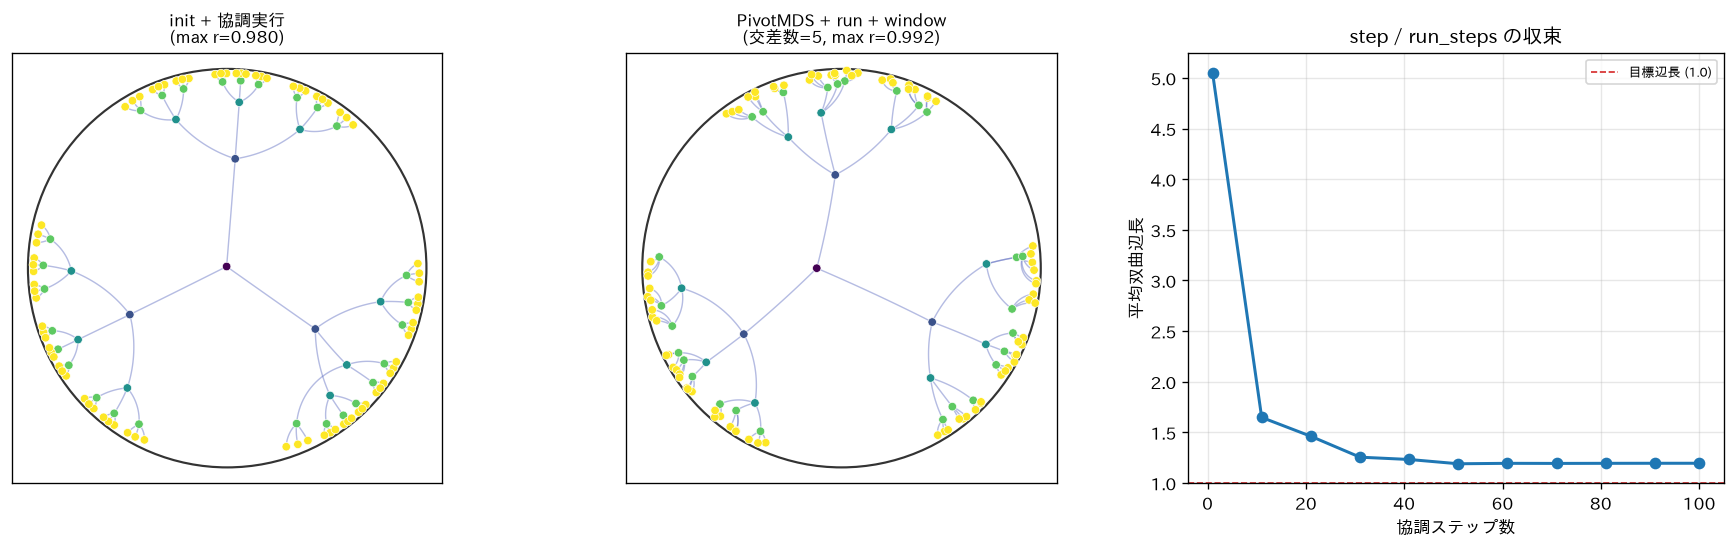

In [ ]:
\
# Balanced 3-ary tree (N=121, E=120): ideal hierarchical topology for hyperbolic space
g_tree = eg.generate_hyperbolic_tree(branching_factor=3, depth=4)
n_tree = g_tree.num_nodes
tree_edges = _unique_undirected_edges(g_tree)

# A) Demonstrate zero-tangent deadlock when starting from zeros
m_deadlock = eg.ManifoldLayout2d.zeros("hyperbolic", n_tree)
eg.SgdSolver.full(g_tree, iterations=100, seed=42).run(m_deadlock)
r_deadlock = np.linalg.norm(m_deadlock.coords(), axis=1).max()

# B) random/init + cooperative stepping (step & run_steps)
m_rand = eg.ManifoldLayout2d.init("hyperbolic", n_tree, scale=0.25, seed=42)
solver_coop = eg.SgdSolver.full(g_tree, iterations=100, seed=42)
mean_edge_dists = []
status_first = solver_coop.step(m_rand)
mean_edge_dists.append(float(np.mean([m_rand.geodesic_distance(u, v) for u, v in tree_edges])))
step_points = [1]
for k in range(1, 100, 10):
    solver_coop.run_steps(m_rand, min(10, 100 - k))
    step_points.append(min(100, k + 10))
    mean_edge_dists.append(float(np.mean([m_rand.geodesic_distance(u, v) for u, v in tree_edges])))
m_rand.center_poincare_centroid()

# C) from_layout_scaled(pivot_mds_init) + run + reset_schedule/run_schedule_window
pmds = eg.pivot_mds_init(g_tree, num_pivots=30, seed=42)
m_pmds = eg.ManifoldLayout2d.from_layout_scaled("hyperbolic", pmds, max_radius=0.7)
t0 = time.perf_counter()
sgd_pmds = eg.SgdSolver.full(g_tree, iterations=100, seed=42)
status_done = sgd_pmds.run(m_pmds)
sgd_pmds.reset_schedule(iterations=40, schedule="linear", seed=42)
sgd_pmds.run_schedule_window(m_pmds, 0, 20)
dt_ms = (time.perf_counter() - t0) * 1000.0
m_pmds.center_poincare_centroid()

# D) Verify all 17 SgdSolver modes (e.g. sgd2) + other manifold solvers (StressMajorization / TsNet)
m_sgd2 = eg.ManifoldLayout2d.init("hyperbolic", n_tree, scale=0.25, seed=42)
solver_sgd2 = eg.SgdSolver.sgd2(g_tree, iterations=40, seed=42)
assert solver_sgd2.supports_manifold
solver_sgd2.run(m_sgd2)

m_sm_hyp = eg.ManifoldLayout2d.init("hyperbolic_lorentz", n_tree, scale=0.3, seed=42)
eg.StressMajorizationSolver.from_graph(g_tree, max_iterations=30).run(m_sm_hyp)
hyp_cross = eg.hyperbolic_crossing_number(g_tree, m_pmds)

r_rand = np.linalg.norm(m_rand.coords(), axis=1).max()
r_pmds = np.linalg.norm(m_pmds.coords(), axis=1).max()
print(f"Tree N={n_tree}, E={g_tree.num_edges}:")
print(f"  zeros() deadlock max radius     : {r_deadlock:.6f}")
print(f"  init() max radius               : {r_rand:.4f} (first step status={status_first!r})")
print(f"  from_layout_scaled() max radius : {r_pmds:.4f} (status={status_done!r}, hyp_crossings={hyp_cross}, {dt_ms:.1f} ms)")
print(f"  sgd2.supports_manifold={solver_sgd2.supports_manifold}, StressMaj(lorentz) finite={m_sm_hyp.is_all_finite()}")

# Depth colors for balanced tree (root=0 -> leaves=4)
nx_tree = nx.balanced_tree(3, 4)
depths = np.array([nx.shortest_path_length(nx_tree, 0, i) for i in range(n_tree)])

fig = plt.figure(figsize=(15.0, 4.6))
ax0 = fig.add_subplot(131)
plot_poincare_disk(g_tree, m_rand, ax=ax0, title=f"init + 協調実行\n(max r={r_rand:.3f})", node_color=depths, node_size=26)
ax1 = fig.add_subplot(132)
plot_poincare_disk(g_tree, m_pmds, ax=ax1, title=f"PivotMDS + run + window\n(交差数={hyp_cross}, max r={r_pmds:.3f})", node_color=depths, node_size=26)
ax2 = fig.add_subplot(133)
ax2.plot(step_points, mean_edge_dists, marker="o", linewidth=1.8, color="#1f77b4")
ax2.axhline(1.0, color="#d62728", linestyle="--", linewidth=1.0, label="目標辺長 (1.0)")
ax2.set_xlabel("協調ステップ数")
ax2.set_ylabel("平均双曲辺長")
ax2.set_title("step / run_steps の収束")
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. 球面レイアウト（$S^2$）の最適化と 3D 大円アーク可視化

`kind="spherical"` では各頂点が経度・余緯度 $(\\lambda, \\phi) \\in [0, 2\\pi) \\times [0, \\pi]$ で表現され、単位球面上の大円距離が最小化されます。
球面の周囲長は $2\\pi$・最大測地線距離（対蹠点間）は $\\pi \\approx 3.1416$ であるため、直径が $\\pi$ を超えるメッシュにはペア距離スケーリング（`SgdSolver.from_pairs`）を併用するとさらに歪みの少ない球面展開が得られます。

ここでは正十二面体グラフ（$N=20, E=30$）と細分化正二十面体メッシュ（$N=42, E=120$）を球面上に配置し、`mplot3d` 上で SLERP 大円アークとともに可視化します。

Dodecahedron edge spherical dist: mean=0.7297, std=0.0002
Subdivided icosahedron (N=162) edge spherical dist: mean=0.2999, spherical_crossings=0, geodesic_distortion=0.7206


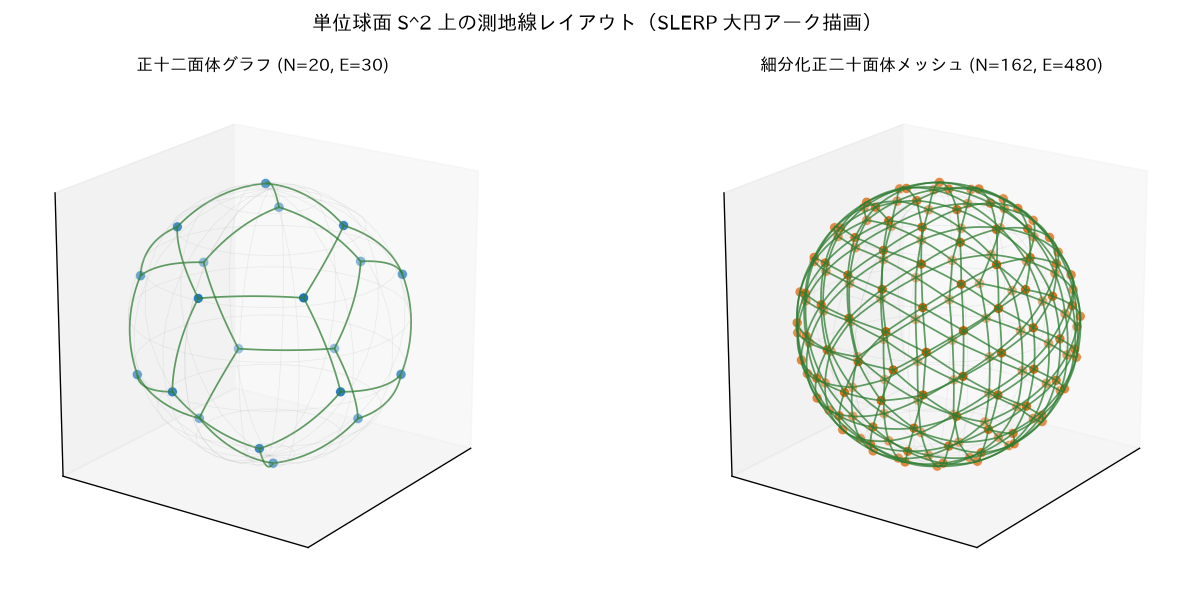

In [ ]:
\
# 1) Dodecahedral graph (diameter=5 -> scale target hop distance so diameter fits ~pi)
g_dodec, _ = from_networkx(nx.dodecahedral_graph())
m_dodec = eg.ManifoldLayout2d.init("spherical", g_dodec.num_nodes, seed=42)
d_dodec = eg.all_pairs_bfs(g_dodec)
iu, ju = np.triu_indices(g_dodec.num_nodes, k=1)
dij_dodec = d_dodec[iu, ju] * (math.pi / float(d_dodec.max()))
wij_dodec = 1.0 / np.maximum(dij_dodec, 1e-3) ** 2
eg.SgdSolver.from_pairs(
    g_dodec.num_nodes, iu.astype(np.uint32), ju.astype(np.uint32), dij_dodec, wij=wij_dodec, iterations=100, seed=42
).run(m_dodec)

# 2) Subdivided icosahedron (N=42, E=120) via built-in generator
g_ico = eg.generate_spherical_icosphere(subdivisions=2)
m_ico = eg.ManifoldLayout2d.init("spherical", g_ico.num_nodes, seed=42)
d_ico = eg.all_pairs_bfs(g_ico)
iu2, ju2 = np.triu_indices(g_ico.num_nodes, k=1)
dij_ico = d_ico[iu2, ju2] * (math.pi / float(d_ico.max()))
wij_ico = 1.0 / np.maximum(dij_ico, 1e-3) ** 2
eg.SgdSolver.from_pairs(
    g_ico.num_nodes, iu2.astype(np.uint32), ju2.astype(np.uint32), dij_ico, wij=wij_ico, iterations=100, seed=42
).run(m_ico)

d_edge_dodec = [m_dodec.geodesic_distance(u, v) for u, v in _unique_undirected_edges(g_dodec)]
d_edge_ico = [m_ico.geodesic_distance(u, v) for u, v in _unique_undirected_edges(g_ico)]
sph_cross_ico = eg.spherical_crossing_number(g_ico, m_ico)
gdist_ico = eg.geodesic_distortion(g_ico, m_ico)
print(f"Dodecahedron edge spherical dist: mean={np.mean(d_edge_dodec):.4f}, std={np.std(d_edge_dodec):.4f}")
print(
    f"Subdivided icosahedron (N={g_ico.num_nodes}) edge spherical dist: "
    f"mean={np.mean(d_edge_ico):.4f}, spherical_crossings={sph_cross_ico}, geodesic_distortion={gdist_ico:.4f}"
)

fig = plt.figure(figsize=(11.5, 5.0))
ax0 = fig.add_subplot(121, projection="3d")
plot_spherical_3d(g_dodec, m_dodec, ax=ax0, title=f"正十二面体グラフ (N={g_dodec.num_nodes}, E={g_dodec.num_edges})")
ax1 = fig.add_subplot(122, projection="3d")
plot_spherical_3d(g_ico, m_ico, ax=ax1, title=f"細分化正二十面体メッシュ (N={g_ico.num_nodes}, E={g_ico.num_edges})", node_color="#d95f02")
fig.suptitle("単位球面 S^2 上の測地線レイアウト（SLERP 大円アーク描画）", fontsize=12)
plt.tight_layout()
plt.show()

\
## 6. トーラスレイアウト（$T^2$）の周期境界・スペクトル位相初期化・自動センタリング

平坦単位トーラス $[0, 1)^2$ 上の最大測地線距離は $\\frac{\\sqrt{2}}{2} \\approx 0.7071$ です。
そのため、生の BFS ホップ距離（$d_{ij} \\ge 1.0$）をそのまま目標距離とする `SgdSolver.full(g)` を大きな周期格子へ適用すると、目標距離が多様体の直径を大幅に超過し、**深刻な自己交差・ねじれ**が発生します。

一方、以下の組み合わせにより、$[0, 1)^2$ 上で**交差数 0 の格子展開**を高精度かつ高速に得られます。
1. `ManifoldLayout2d.torus_spectral_phase_init(g)` でラプラシアン固有ベクトルの周期位相から初期配置を生成し、`SgdSolver.from_pairs(...)` で $0.1$ 倍スケーリング済み距離を最適化する。
2. `m_torus.torus_auto_pan(g)` でエッジの境界跨ぎが最小となるように並進センタリング（アライメント）し、`torus_layout_edge_segments(g, m_torus)` や `torus_crossing_number(g, m_torus)` / `crossing_edges_torus(g, m_torus)`（`ManifoldLayout2d` 直接対応）で評価・可視化する。

10x10 Torus Grid (N=100, E=200):
  Unscaled SgdSolver.full      -> torus_crossing_number = 2228.0, len(crossing_edges_torus) = 2228
  SpectralInit + Scaled + Pan  -> torus_crossing_number = 0.0, geodesic_distortion = 0.9207, edge_segments = 220


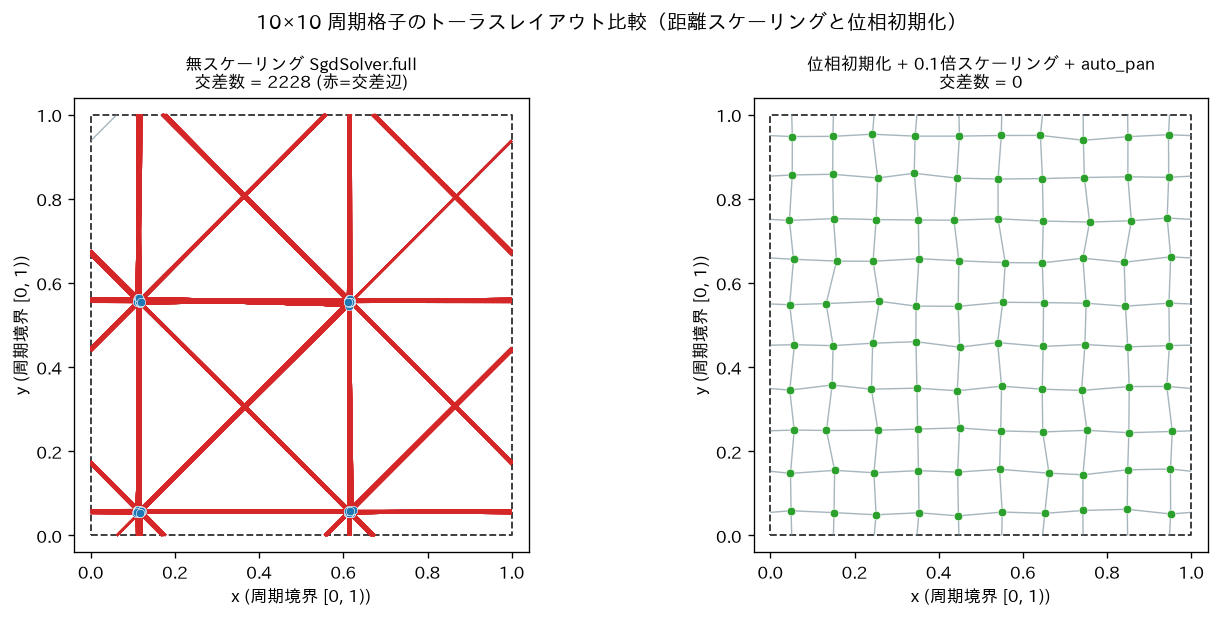

In [ ]:
\
# 10x10 periodic torus grid (N=100, E=200)
g_torus = eg.generate_torus_grid(10, 10, triangulated=False)

# A) Unscaled SgdSolver.full (hop distances >= 1.0 exceed torus diameter sqrt(2)/2 ~ 0.7071)
m_torus_unscaled = eg.ManifoldLayout2d.init("torus", g_torus.num_nodes, seed=42)
eg.SgdSolver.full(g_torus, iterations=100, seed=42).run(m_torus_unscaled)
c_unscaled = eg.torus_crossing_number(g_torus, m_torus_unscaled)
edges_cross_unscaled = eg.crossing_edges_torus(g_torus, m_torus_unscaled)

# B) Spectral phase init + Scaled SgdSolver.from_pairs + torus_auto_pan
bfs_dists = eg.all_pairs_bfs(g_torus)
iu, ju = np.triu_indices(g_torus.num_nodes, k=1)
dij_scaled = bfs_dists[iu, ju] * 0.1
wij_scaled = 1.0 / np.maximum(dij_scaled, 1e-4) ** 2

m_torus_scaled = eg.ManifoldLayout2d.torus_spectral_phase_init(g_torus, seed=42)
eg.SgdSolver.from_pairs(
    g_torus.num_nodes, iu.astype(np.uint32), ju.astype(np.uint32), dij_scaled, wij=wij_scaled, iterations=120, schedule="linear", seed=42
).run(m_torus_scaled)
m_torus_panned = m_torus_scaled.torus_auto_pan(g_torus)
c_scaled = eg.torus_crossing_number(g_torus, m_torus_panned)
edges_cross_scaled = eg.crossing_edges_torus(g_torus, m_torus_panned)
tor_segs = eg.torus_layout_edge_segments(g_torus, m_torus_panned)
gd_torus = eg.geodesic_distortion(g_torus, m_torus_panned)

print(f"10x10 Torus Grid (N={g_torus.num_nodes}, E={g_torus.num_edges}):")
print(f"  Unscaled SgdSolver.full      -> torus_crossing_number = {c_unscaled:.1f}, len(crossing_edges_torus) = {len(edges_cross_unscaled)}")
print(
    f"  SpectralInit + Scaled + Pan  -> torus_crossing_number = {c_scaled:.1f}, "
    f"geodesic_distortion = {gd_torus:.4f}, edge_segments = {len(tor_segs)}"
)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.2))
plot_torus_2d(
    g_torus,
    m_torus_unscaled,
    ax=axes[0],
    crossings=edges_cross_unscaled,
    title=f"無スケーリング SgdSolver.full\n交差数 = {int(c_unscaled)} (赤=交差辺)",
)
plot_torus_2d(
    g_torus,
    m_torus_panned,
    ax=axes[1],
    crossings=edges_cross_scaled,
    title=f"位相初期化 + 0.1倍スケーリング + auto_pan\n交差数 = {int(c_scaled)}",
    node_color="#2ca02c",
)
fig.suptitle("10×10 周期格子のトーラスレイアウト比較（距離スケーリングと位相初期化）", fontsize=12)
plt.tight_layout()
plt.show()

\
## 7. `resistance_curvature_flow` による多様体（幾何）の自動推薦

グラフの構造から「どの多様体に埋め込むのが適切か」を自動で判定したい場合、`resistance_curvature_flow(graph, ...)` の結果オブジェクトが提供する `suggested_geometry` / `suggested_manifold` を利用できます。

- **負の平均リンク曲率** (`mean_link_curvature < -0.05`) → `"hyperbolic"`（木構造・階層ネットワーク）
- **正の強い平均リンク曲率** (`mean_link_curvature > 0.2`) → `"spherical"`（凸多面体・球面メッシュ）
- **葉なし・ほぼ正則次数・曲率分散が極小** (`leaf_fraction == 0`, `deg_cv < 0.02`, `std_link_curvature <= 0.05`) → `"torus"`
- それ以外 → `"euclidean"`（`suggested_manifold` は `None`）

> **自動厳密計算 (`exact_max_nodes=256`, `jl_dim=128`)**: 既定の `exact_max_nodes` は **`256`** に設定されているため、$N=100$ の `10x10` トーラス格子は既定設定のままで自動的に厳密計算 (`used_exact=True`) が選ばれ、正確に `"torus"` と判定されます（対照として `exact=False` で JL ランダム射影近似を強制した場合との違いも確認できます）。

Graph                              N  Exact  mean_link_k  std_link_k     geometry     manifold
-----------------------------------------------------------------------------------------------
Balanced Tree (3,3)               40   True      -1.6906      0.8393   hyperbolic   hyperbolic
Dodecahedral (N=20)               20   True       0.3158      0.0000    spherical    spherical
Torus 10x10 (default, N<=256)    100   True       0.0808      0.0000        torus        torus
Torus 10x10 (JL forced)          100  False       0.0821      0.1152        torus        torus


3_elt (Euclidean mesh)          4720  False      -0.0223      0.2177    euclidean         None


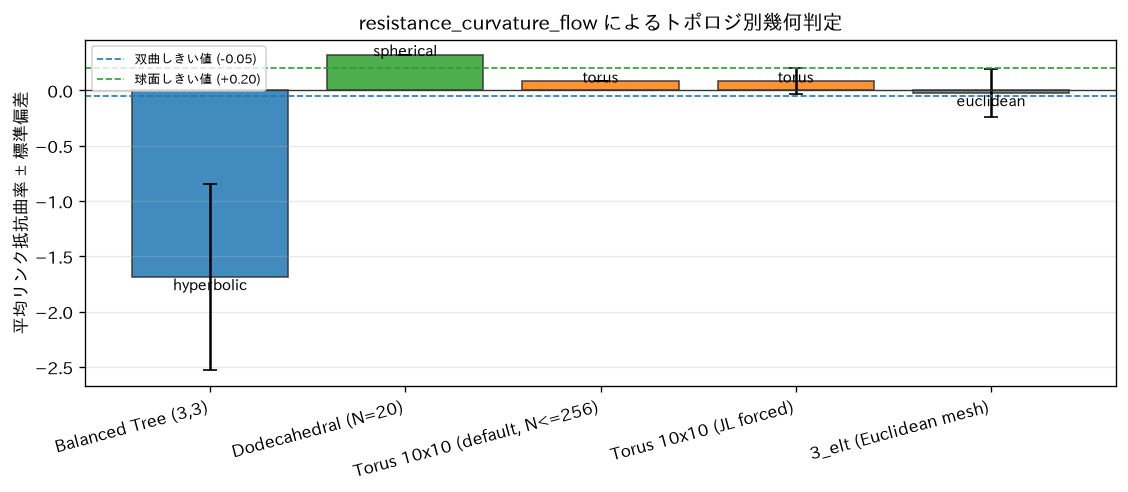

In [ ]:
\
g_tree_small = eg.generate_hyperbolic_tree(branching_factor=3, depth=3)  # N=40
g_euc = eg.load_dataset("3_elt")

cases = [
    ("Balanced Tree (3,3)", g_tree_small, None),
    ("Dodecahedral (N=20)", g_dodec, None),
    ("Torus 10x10 (default, N<=256)", g_torus, None),
    ("Torus 10x10 (JL forced)", g_torus, False),
    ("3_elt (Euclidean mesh)", g_euc, None),
]

names_plot = []
mean_kappas = []
std_kappas = []
geoms = []

print(f"{'Graph':<30} {'N':>5} {'Exact':>6} {'mean_link_k':>12} {'std_link_k':>11} {'geometry':>12} {'manifold':>12}")
print("-" * 95)
for label, gr, exact_flag in cases:
    rcf = eg.resistance_curvature_flow(gr, steps=2, exact=exact_flag)
    print(
        f"{label:<30} {gr.num_nodes:>5} {str(rcf.used_exact):>6} {rcf.mean_link_curvature:>12.4f} "
        f"{rcf.std_link_curvature:>11.4f} {rcf.suggested_geometry:>12} {str(rcf.suggested_manifold):>12}"
    )
    names_plot.append(label)
    mean_kappas.append(rcf.mean_link_curvature)
    std_kappas.append(rcf.std_link_curvature)
    geoms.append(rcf.suggested_geometry)

color_map = {"hyperbolic": "#1f77b4", "spherical": "#2ca02c", "torus": "#ff7f0e", "euclidean": "#7f7f7f"}
bar_colors = [color_map[g_name] for g_name in geoms]

fig, ax = plt.subplots(figsize=(9.5, 4.2))
x_pos = np.arange(len(names_plot))
bars = ax.bar(x_pos, mean_kappas, yerr=std_kappas, capsize=4, color=bar_colors, alpha=0.85, edgecolor="#333333")
ax.axhline(-0.05, color="#1f77b4", linestyle="--", linewidth=1.0, label="双曲しきい値 (-0.05)")
ax.axhline(0.20, color="#2ca02c", linestyle="--", linewidth=1.0, label="球面しきい値 (+0.20)")
ax.axhline(0.0, color="#333333", linewidth=0.8)
for bar, g_name in zip(bars, geoms):
    y_val = bar.get_height()
    offset = 0.04 if y_val >= 0 else -0.07
    ax.text(bar.get_x() + bar.get_width() / 2.0, y_val + offset, g_name, ha="center", va="center", fontsize=9, fontweight="bold")
ax.set_xticks(x_pos)
ax.set_xticklabels(names_plot, rotation=15, ha="right")
ax.set_ylabel("平均リンク抵抗曲率 ± 標準偏差")
ax.set_title("resistance_curvature_flow によるトポロジ別幾何判定")
ax.legend(loc="upper left", fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()